# Dự án: Phân tích & Dự đoán Nghỉ việc (Employee Attrition)
## Kết hợp toàn diện: EDA + Tiền xử lý + Tối ưu Ngưỡng & Ratio + Áp dụng 3 Phương pháp Feature Selection (Filter, Wrapper, Embedded) cho TỪNG MÔ HÌNH
---
**Bộ dữ liệu:** `attritioon.csv`

### Nội dung chi tiết trong Notebook:
1. **Khám phá & Đánh giá dữ liệu (EDA):** Phân phối nhãn Attrition, Histogram tất cả biến số (kèm độ lệch Skewness), Boxplot ngoại lệ, Ma trận tương quan Heatmap, Tỷ lệ nghỉ việc theo biến phân loại.
2. **Tiền xử lý dữ liệu:** Log-transform (`np.log1p`) biến lệch phải (skew > 0.75), Encoding với `ColumnTransformer`, chia train/test stratified (80/20).
3. **Xử lý mất cân bằng lớp:** Tính `ratio = (ở lại) / (nghỉ việc)` (~5.2:1) làm trọng số bù.
4. **Áp dụng ĐẦY ĐỦ 4 cấu hình đặc trưng cho TỪNG MÔ HÌNH:**
   - **Mô hình 1: Logistic Regression** (Toàn bộ đặc trưng, Filter - MI, Wrapper - RFE, Embedded - L1/Lasso)
   - **Mô hình 2: Random Forest** (Toàn bộ đặc trưng, Filter - MI, Wrapper - RFE, Embedded - Tree Importance)
   - **Mô hình 3: XGBoost** (Toàn bộ đặc trưng, Filter - MI, Wrapper - RFE, Embedded - XGB Importance)
5. **Tối ưu ngưỡng quyết định (Threshold Tuning):** Dùng `cross_val_predict` trên tập train để tìm ngưỡng đạt mục tiêu **Recall >= 0.70**, tránh tình trạng Recall = 0 do mất cân bằng lớp.
6. **So sánh toàn diện:** Bảng tổng kết 12 kịch bản + Biểu đồ trực quan hóa F1-Score, Recall và ROC Curve.

## 1. Import Thư Viện Cần Thiết

In [2]:
import pandas as pd
import numpy as np
import math
import warnings
warnings.filterwarnings("ignore")

import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import skew
from functools import partial

from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import (
    classification_report, accuracy_score, f1_score,
    precision_score, recall_score, roc_auc_score, confusion_matrix, roc_curve
)
from sklearn.feature_selection import SelectKBest, mutual_info_classif, RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

print("Import thư viện thành công!")

Import thư viện thành công!


## 2. Đọc Dữ Liệu & Khảo Sát Ban Đầu

In [3]:
df = pd.read_csv("attritioon.csv")
print(f"Kích thước dữ liệu gốc: {df.shape}")
df.head()

Kích thước dữ liệu gốc: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,40,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,51,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,36,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,36,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,28,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [4]:
# Kiểm tra giá trị rỗng và trùng lặp
print("Số lượng giá trị null:", df.isnull().sum().sum())
print("Số dòng trùng lặp:", df.duplicated().sum())

# Loại bỏ các cột không mang giá trị dự đoán:
# - EmployeeCount, StandardHours: Cột hằng số (variance = 0)
# - EmployeeNumber: Cột ID
# - Over18: Tất cả nhân viên đều trên 18 tuổi ('Y')
df.drop(['EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours'], axis=1, inplace=True)
print(f"Kích thước sau khi loại cột: {df.shape}")

# Phân loại cột
cat_col = [col for col in df.columns if not pd.api.types.is_numeric_dtype(df[col])]
num_col = [col for col in df.columns if pd.api.types.is_numeric_dtype(df[col])]
print('Cột phân loại:', cat_col)
print('Cột số:', num_col)

Số lượng giá trị null: 0
Số dòng trùng lặp: 0
Kích thước sau khi loại cột: (1470, 31)
Cột phân loại: ['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
Cột số: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


## 3. Khám Phá Dữ Liệu Trực Quan (EDA)

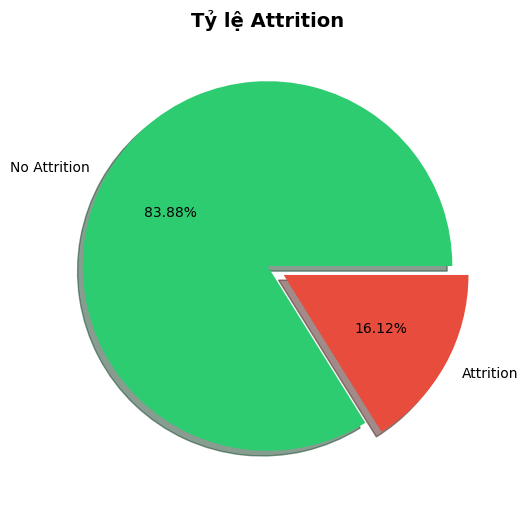

Attrition
No     1233
Yes     237
Name: count, dtype: int64
Tỷ lệ nghỉ việc: 16.12%


In [5]:
# 3.1 Tỷ lệ Attrition (Mất cân bằng lớp)
plt.figure(figsize=(6, 6))
plt.pie(
    df['Attrition'].value_counts(),
    labels=['No Attrition', 'Attrition'],
    autopct='%.2f%%',
    shadow=True,
    colors=['#2ecc71', '#e74c3c'],
    explode=(0, 0.1)
)
plt.title('Tỷ lệ Attrition', fontsize=14, fontweight='bold')
plt.show()

print(df['Attrition'].value_counts())
print(f"Tỷ lệ nghỉ việc: {(df['Attrition'] == 'Yes').mean()*100:.2f}%")

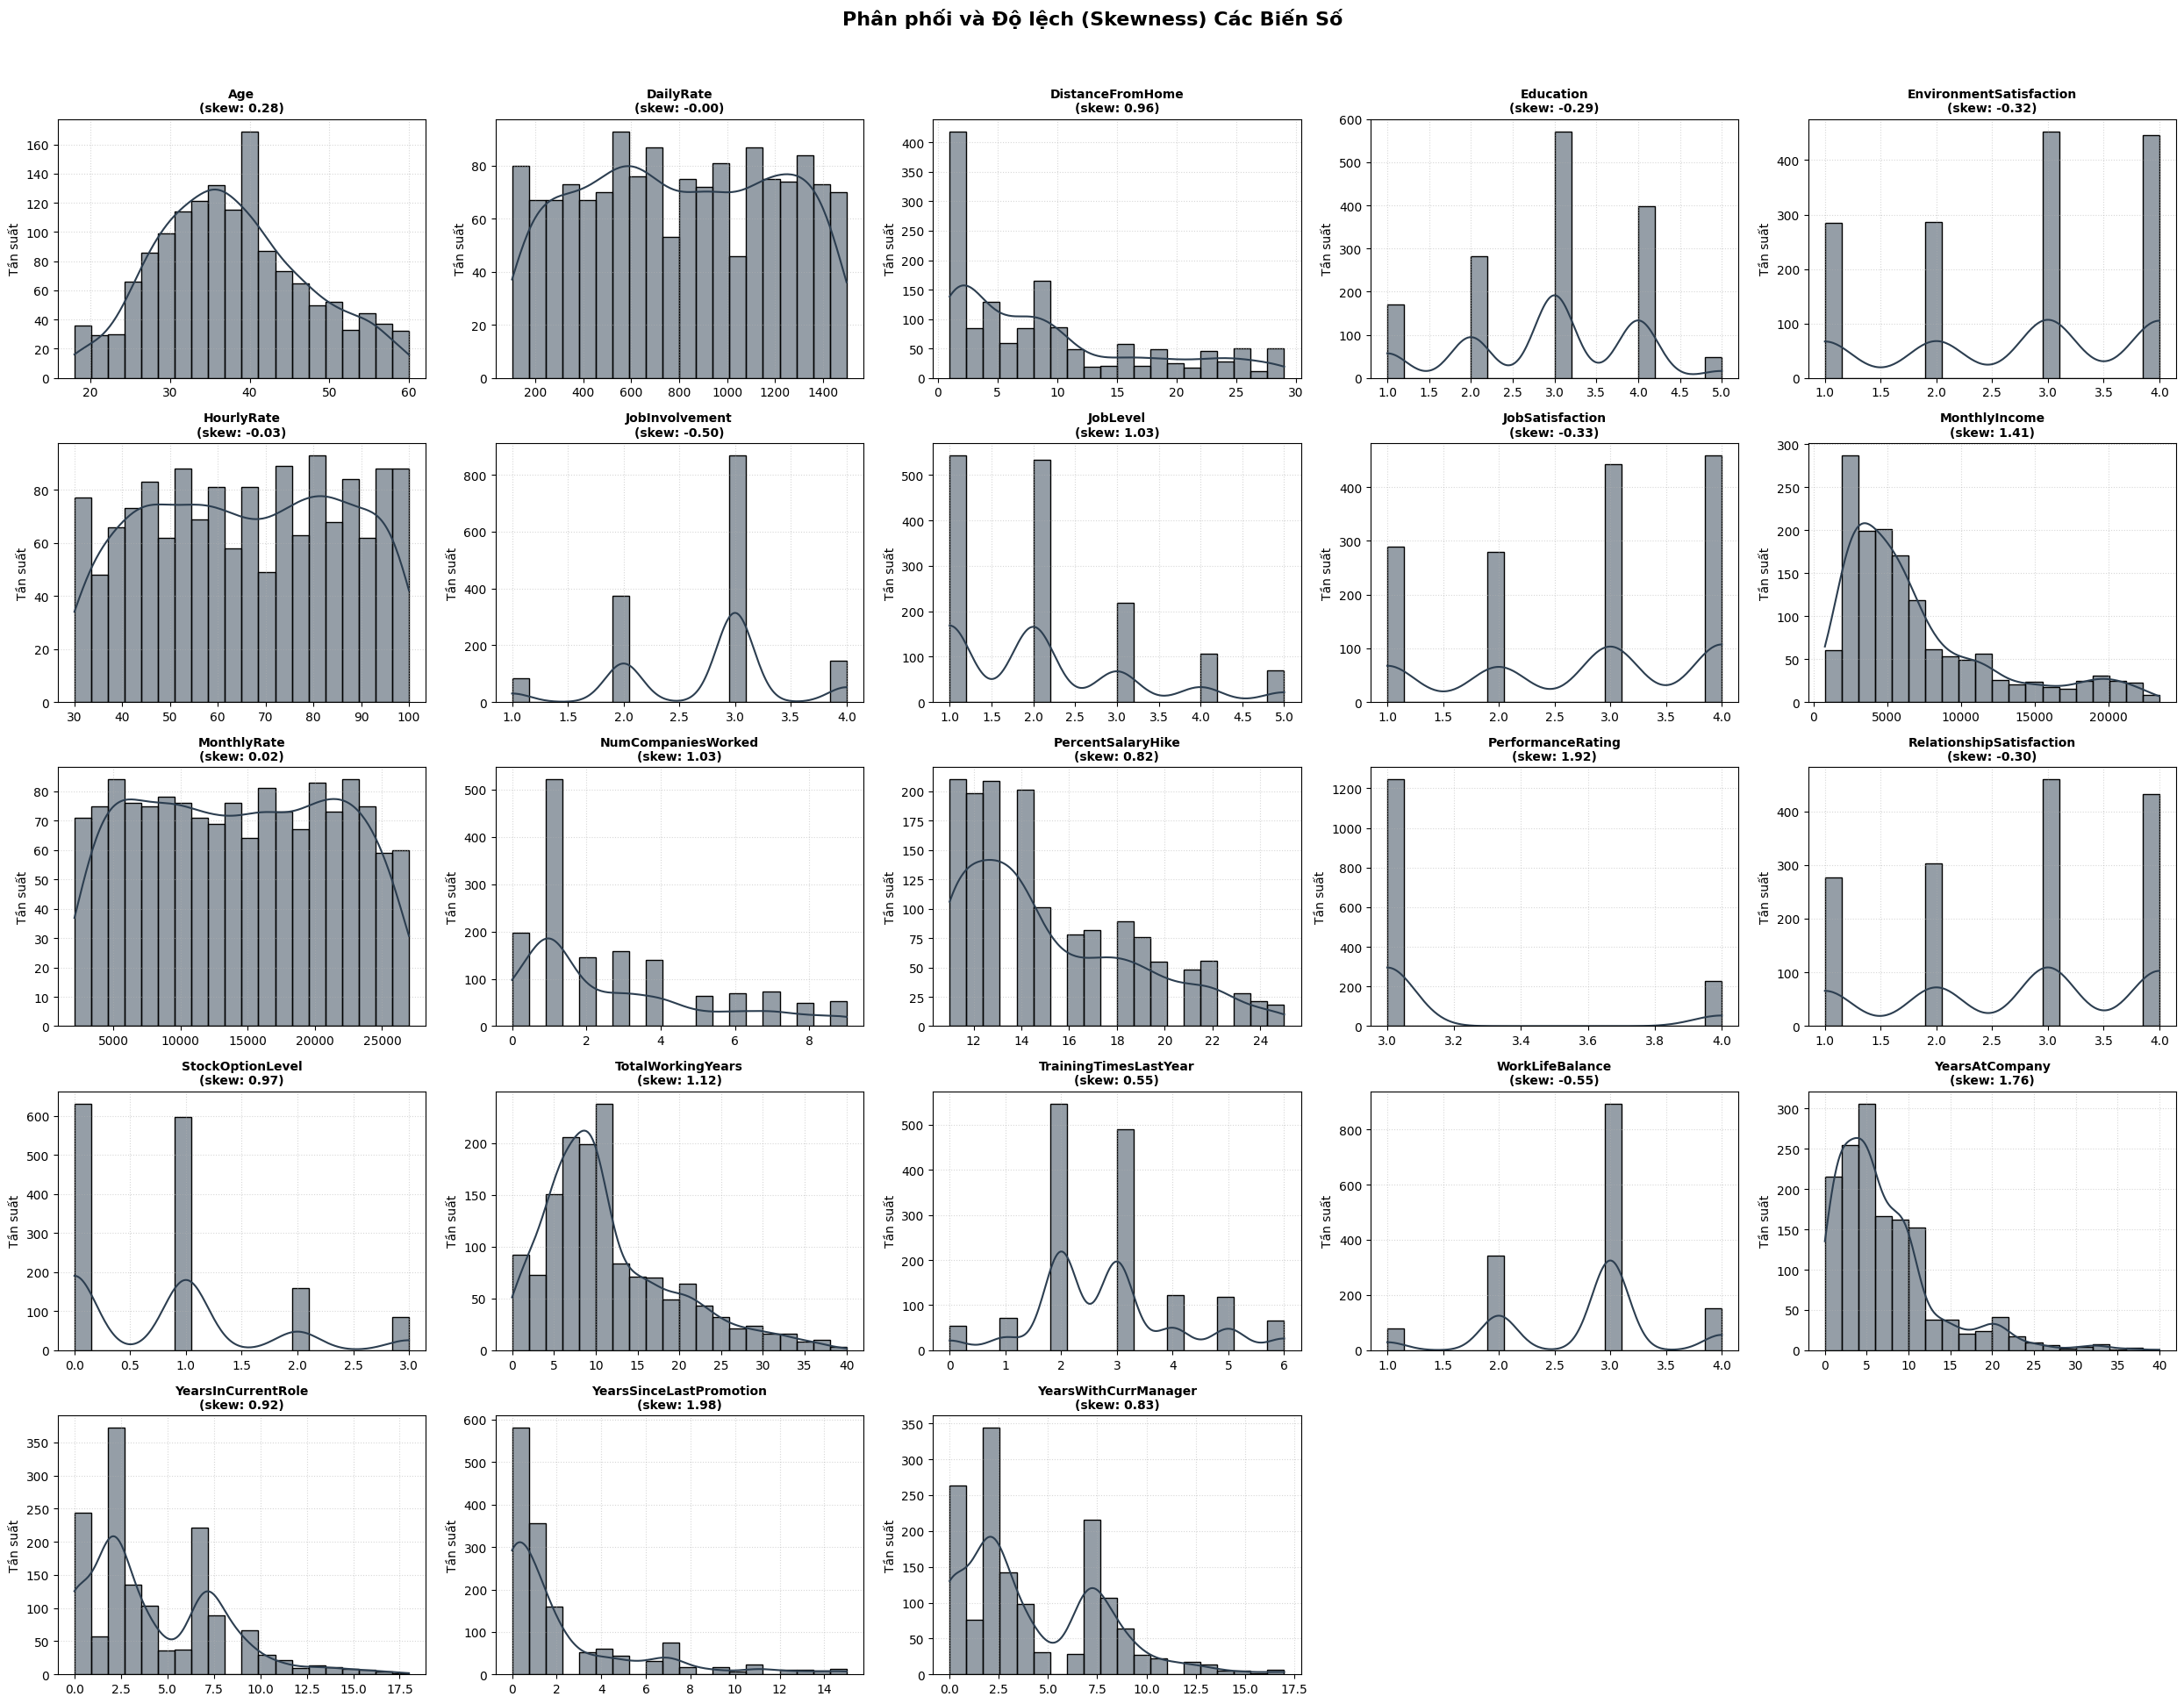

In [6]:
# 3.2 Phân phối của tất cả các biến số và độ lệch (Skewness)
plots_per_row = 5
total_plots = len(num_col)
n_rows = math.ceil(total_plots / plots_per_row)

fig, axes = plt.subplots(n_rows, plots_per_row, figsize=(5 * plots_per_row, 3.8 * n_rows))
axes = axes.flatten()

for i, col in enumerate(num_col):
    sk = df[col].skew()
    sns.histplot(df[col], ax=axes[i], kde=True, color='#2c3e50', bins=20)
    axes[i].set_title(f"{col}\n(skew: {sk:.2f})", fontsize=10, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Tần suất')
    axes[i].grid(True, linestyle=':', alpha=0.5)

for j in range(total_plots, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Phân phối và Độ lệch (Skewness) Các Biến Số', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

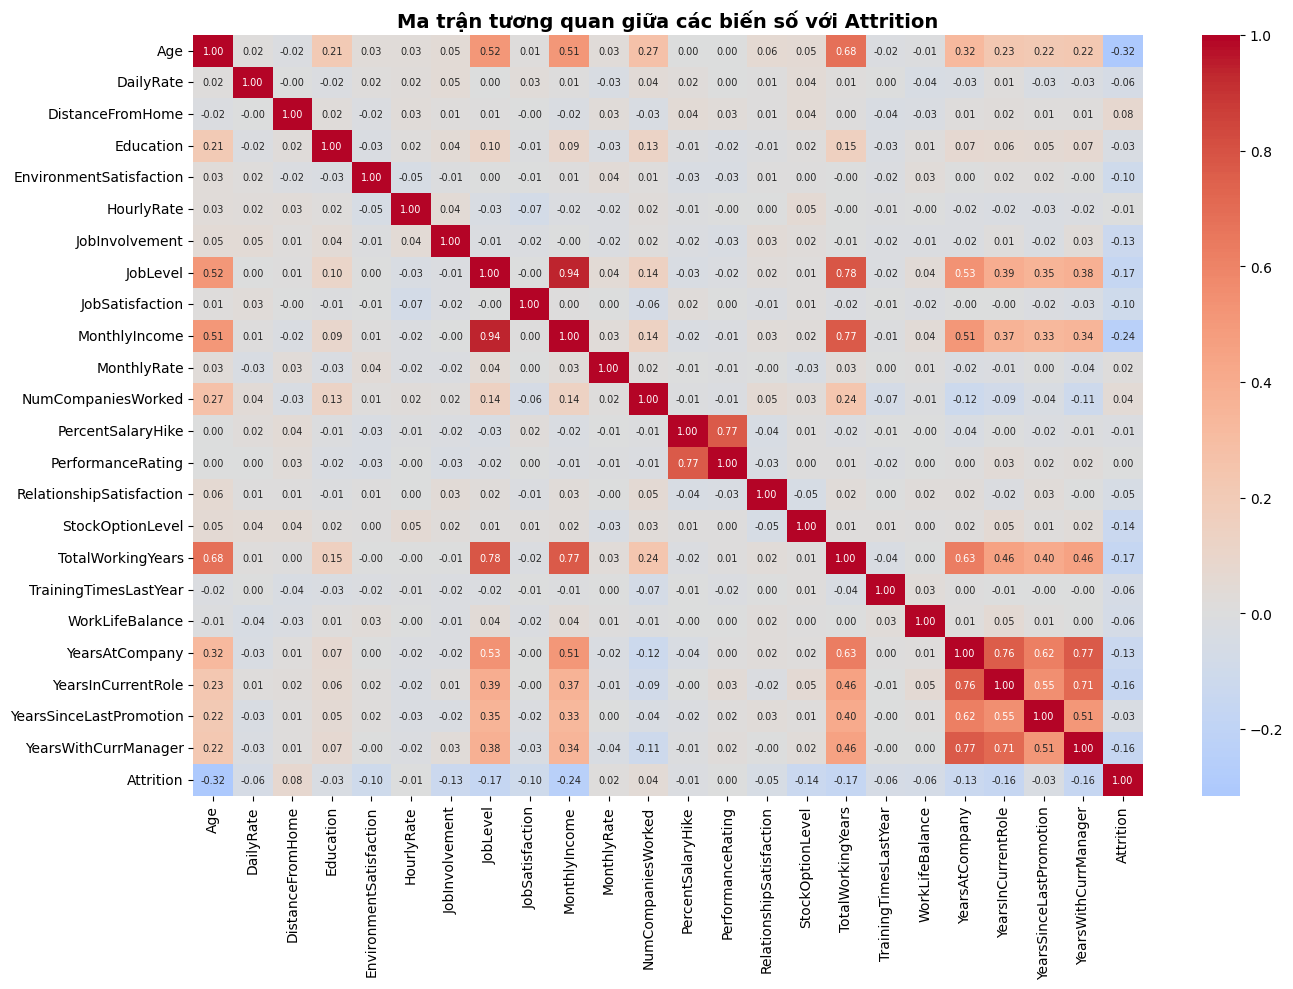

In [7]:
# 3.3 Ma trận tương quan Heatmap
df_corr = df[num_col].copy()
df_corr['Attrition'] = df['Attrition'].map({"No": 0, "Yes": 1})

plt.figure(figsize=(14, 10))
sns.heatmap(df_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 7}, center=0)
plt.title("Ma trận tương quan giữa các biến số với Attrition", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

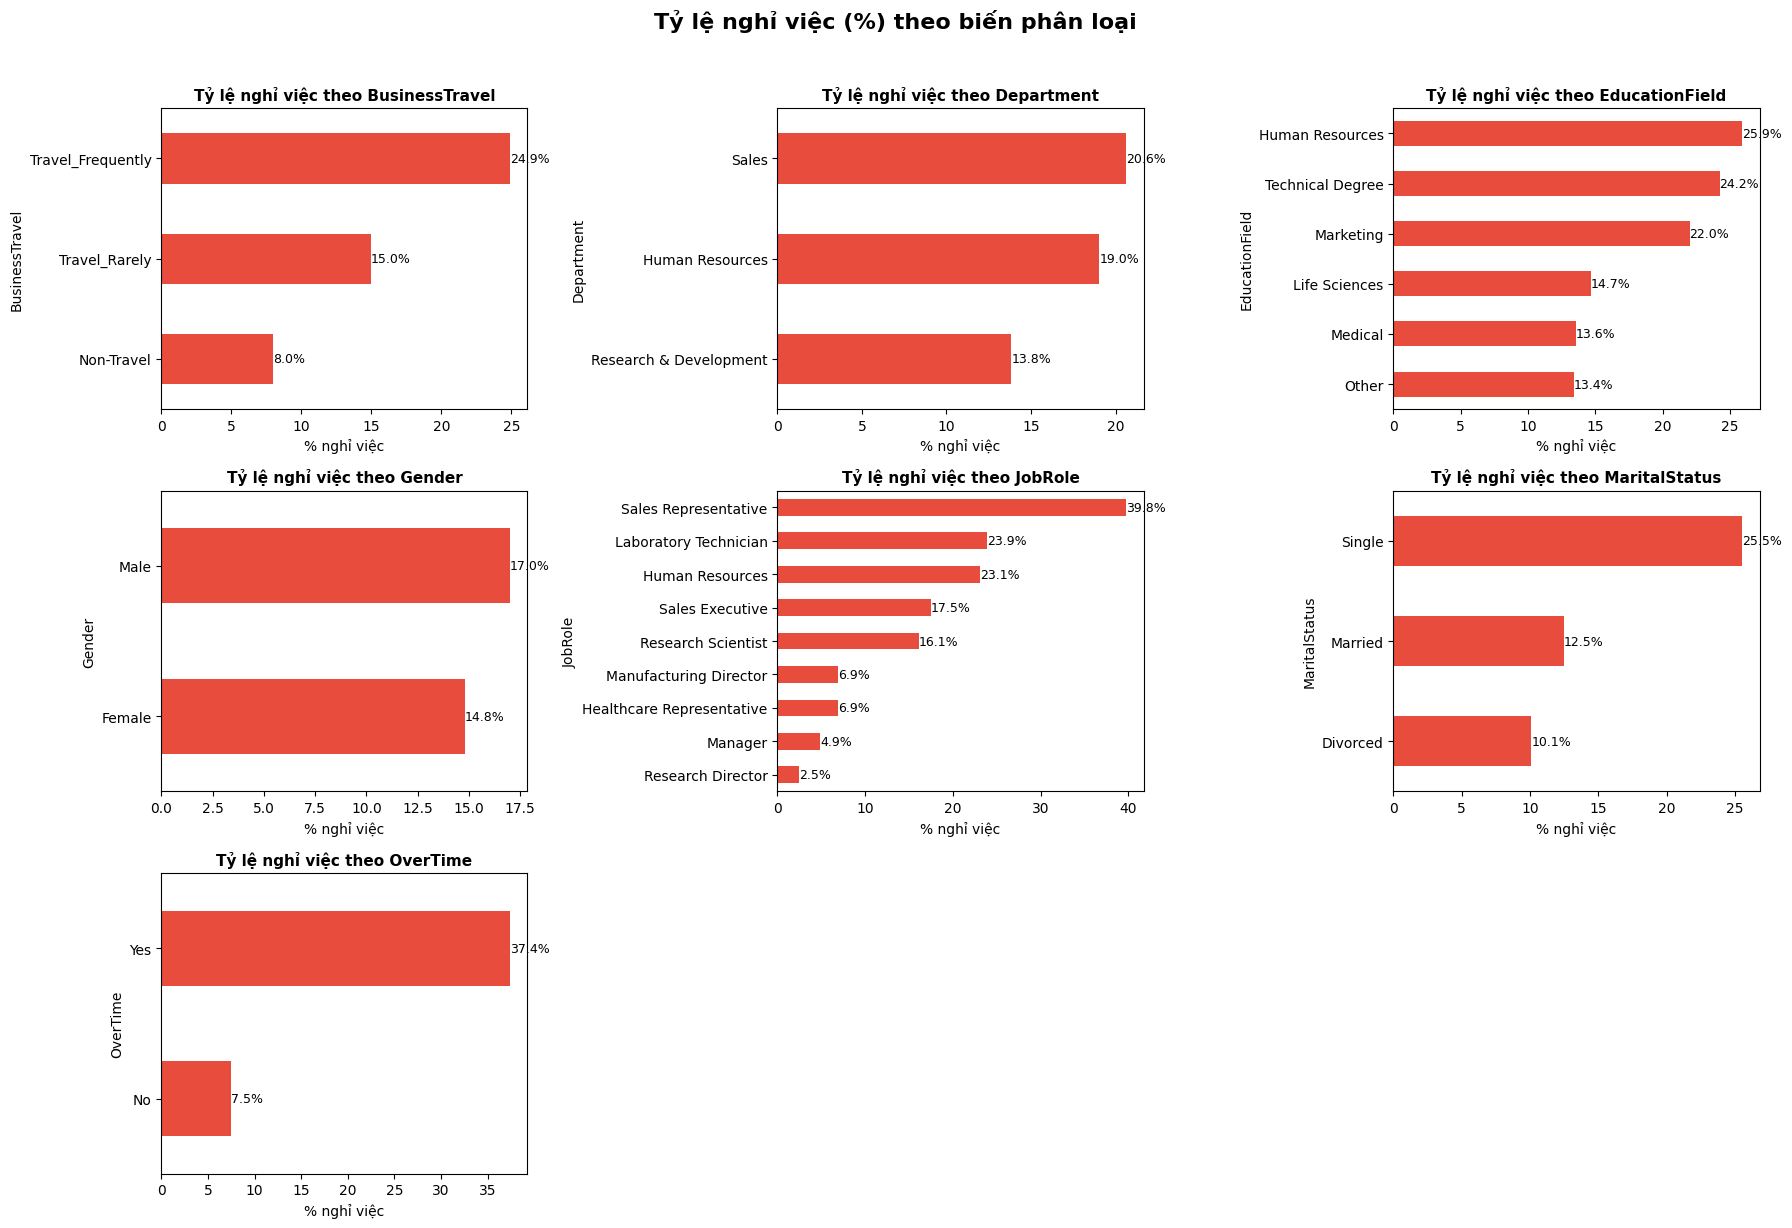

In [8]:
# 3.4 Tỷ lệ nghỉ việc theo từng biến phân loại
cat_features = [c for c in cat_col if c != 'Attrition']
n_cat = len(cat_features)
fig, axes = plt.subplots(math.ceil(n_cat / 3), 3, figsize=(18, math.ceil(n_cat / 3) * 4))
axes = axes.flatten()

for i, col in enumerate(cat_features):
    ty_le = df.groupby(col)['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100)
    ty_le.sort_values().plot(kind='barh', ax=axes[i], color='#e74c3c')
    axes[i].set_title(f"Tỷ lệ nghỉ việc theo {col}", fontsize=11, fontweight='bold')
    axes[i].set_xlabel("% nghỉ việc")
    for p in axes[i].patches:
        axes[i].annotate(f"{p.get_width():.1f}%", (p.get_width(), p.get_y() + p.get_height()/2),
                         ha='left', va='center', fontsize=9)

for j in range(n_cat, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Tỷ lệ nghỉ việc (%) theo biến phân loại', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 4. Tiền Xử Lý Dữ Liệu

In [9]:
# 4.1 Biến đổi Log-transform (np.log1p) các biến bị lệch phải (skewness > 0.75)
df_log = df.copy()
skewed_cols = []
for col in num_col:
    if df_log[col].skew() > 0.75 and (df_log[col] >= 0).all():
        df_log[col] = np.log1p(df_log[col])
        skewed_cols.append(col)

print("Các cột được áp dụng log-transform:", skewed_cols)

Các cột được áp dụng log-transform: ['DistanceFromHome', 'JobLevel', 'MonthlyIncome', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'StockOptionLevel', 'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [10]:
# 4.2 Thiết lập Pipeline Mã hóa (Encoding) & Chia Train/Test
ordinal_features = ["BusinessTravel", "OverTime"]
ordinal_categories = [
    ["Non-Travel", "Travel_Rarely", "Travel_Frequently"],
    ["No", "Yes"]
]

ordinal_features2 = ["MaritalStatus"]
ordinal_categories2 = [["Single", "Married", "Divorced"]]

nominal_features = ["Department", "EducationField", "JobRole"]
binary_features = ["Gender"]

preprocessor = ColumnTransformer(
    transformers=[
        ("ordinal",  OrdinalEncoder(categories=ordinal_categories),  ordinal_features),
        ("ordinal2", OrdinalEncoder(categories=ordinal_categories2), ordinal_features2),
        ("binary",   OrdinalEncoder(),                               binary_features),
        ("nominal",  OneHotEncoder(drop="first", sparse_output=False), nominal_features),
    ],
    remainder="passthrough",
)

X = df_log.drop('Attrition', axis=1)
y = df['Attrition'].map({"No": 0, "Yes": 1})

# Chia tập train/test trước khi mã hóa để chống Data Leakage
Xtrain, Xtest, ytrain, ytest = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train_encoded = preprocessor.fit_transform(Xtrain)
X_test_encoded  = preprocessor.transform(Xtest)

feature_names = preprocessor.get_feature_names_out()
X_train_df = pd.DataFrame(X_train_encoded, columns=feature_names, index=Xtrain.index)
X_test_df  = pd.DataFrame(X_test_encoded,  columns=feature_names, index=Xtest.index)

print(f"X_train_df shape: {X_train_df.shape}")
print(f"X_test_df shape : {X_test_df.shape}")

X_train_df shape: (1176, 42)
X_test_df shape : (294, 42)


In [11]:
# 4.3 Tính Ratio bù mất cân bằng lớp & Baseline Accuracy
ratio = (ytrain == 0).sum() / (ytrain == 1).sum()
print(f"Tỷ lệ số người Ở Lại / Nghỉ Việc (ratio): {ratio:.2f}")
print(f"Baseline accuracy (nếu đoán toàn bộ ở lại): {(1 - ytest.mean())*100:.2f}%")

# 4.4 Chuẩn hóa StandardScaler (BẮT BUỘC cho Logistic Regression)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_df), columns=feature_names, index=Xtrain.index)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test_df),  columns=feature_names, index=Xtest.index)

print("Chuẩn hóa dữ liệu xong!")

Tỷ lệ số người Ở Lại / Nghỉ Việc (ratio): 5.19
Baseline accuracy (nếu đoán toàn bộ ở lại): 84.01%
Chuẩn hóa dữ liệu xong!


## ⚠️ GIẢI THÍCH: TẠI SAO PHƯƠNG PHÁP LỌC VÀO LOGISTIC REGRESSION LẠI DỄ BỊ RECALL = 0?

Nếu bạn từng gặp trường hợp **Logistic Regression dự đoán nhãn 1 (Nghỉ việc) có Recall = 0**, nguyên nhân bắt nguồn từ 3 lý do kỹ thuật sau:

1. **Thiếu tham số `class_weight='balanced'`:**
   - Tỷ lệ nghỉ việc chỉ chiếm ~16%, còn 84% là ở lại.
   - Nếu dùng `LogisticRegression()` mặc định (không có `class_weight='balanced'`), hàm mất mát sẽ bị chi phối bởi 84% mẫu nhãn 0. Mô hình học cách dự đoán **TẤT CẢ là 0** để đạt Accuracy 84%.
   - Kết quả: $TP = 0 \implies \text{Recall} = \frac{TP}{TP + FN} = 0.0$!

2. **Dữ liệu chưa được chuẩn hóa (`StandardScaler`):**
   - Phương pháp Lọc (Filter) chọn ra các đặc trưng có thang đo rất lệch nhau (ví dụ: `MonthlyIncome` hàng ngàn, trong khi biến mã hóa `OverTime` chỉ là 0 hoặc 1).
   - Khi không scale, thuật toán tối ưu `lbfgs` không hội tụ, gradient bị nổ và hàm sigmoid bị bão hòa, đẩy toàn bộ xác suất dự đoán $P(Y=1)$ về gần 0.

3. **Ngưỡng quyết định (Decision Threshold) 0.5 quá cao đối với dữ liệu mất cân bằng:**
   - Với dữ liệu lệch tỷ lệ, phần lớn xác suất dự đoán chỉ nằm trong khoảng 0.1 - 0.3. Nếu dùng ngưỡng mặc định 0.5, không có mẫu nào vượt qua ngưỡng $\implies$ dự đoán toàn nhãn 0 $\implies$ Recall = 0.

> 👉 **GIẢI PHÁP TRIỆT ĐỂ ĐÃ TRIỂN KHAI DƯỚI ĐÂY:**
> - Luôn truyền `class_weight='balanced'` cho Logistic Regression.
> - Luôn huấn luyện Logistic Regression trên tập dữ liệu đã chuẩn hóa `X_train_scaled`.
> - Tối ưu hóa **Ngưỡng quyết định** qua `cross_val_predict` trên tập train để bảo đảm **Recall >= 0.70**.

In [12]:
# Hàm dùng chung để đánh giá và tối ưu ngưỡng quyết định cho từng mô hình
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
muc_tieu_recall = 0.70
bang_tong_hop = []

def danh_gia_mo_hinh(model, X_tr, y_tr, X_te, y_te, ten_mo_hinh, ten_pp, danh_sach_cot):
    """
    Huấn luyện mô hình trên danh_sach_cot, in các chỉ số ở ngưỡng mặc định 0.5,
    sau đó tìm ngưỡng tối ưu trên train và đánh giá lại trên test.
    """
    X_train_sub = X_tr[danh_sach_cot]
    X_test_sub  = X_te[danh_sach_cot]
    
    # Fit mô hình
    model.fit(X_train_sub, y_tr)
    
    # 1. Đánh giá ở ngưỡng mặc định 0.5
    xs_test = model.predict_proba(X_test_sub)[:, 1]
    y_pred_05 = (xs_test >= 0.5).astype(int)
    
    # 2. Tìm ngưỡng tối ưu trên train qua kiểm định chéo StratifiedKFold
    xs_train_cv = cross_val_predict(model, X_train_sub, y_tr, cv=cv, method='predict_proba')[:, 1]
    
    nguong_opt = 0.5
    precision_max = 0
    for th in np.arange(0.05, 0.95, 0.01):
        pred_tr = (xs_train_cv >= th).astype(int)
        r = recall_score(y_tr, pred_tr, zero_division=0)
        p = precision_score(y_tr, pred_tr, zero_division=0)
        if r >= muc_tieu_recall and p > precision_max:
            precision_max = p
            nguong_opt = th
            
    # Đánh giá ở ngưỡng tối ưu
    y_pred_opt = (xs_test >= nguong_opt).astype(int)
    
    acc_opt = accuracy_score(y_te, y_pred_opt)
    rec_opt = recall_score(y_te, y_pred_opt, zero_division=0)
    pre_opt = precision_score(y_te, y_pred_opt, zero_division=0)
    f1_opt  = f1_score(y_te, y_pred_opt, zero_division=0)
    auc     = roc_auc_score(y_te, xs_test)
    
    print(f"\n{'='*65}")
    print(f"MÔ HÌNH: {ten_mo_hinh} | PHƯƠNG PHÁP: {ten_pp} ({len(danh_sach_cot)} đặc trưng)")
    print(f"{'='*65}")
    print(f"--- Kết quả với NGƯỠNG MẶC ĐỊNH 0.5 ---")
    print(f"Recall: {recall_score(y_te, y_pred_05, zero_division=0):.4f} | Precision: {precision_score(y_te, y_pred_05, zero_division=0):.4f} | F1: {f1_score(y_te, y_pred_05, zero_division=0):.4f} | Accuracy: {accuracy_score(y_te, y_pred_05):.4f}")
    
    print(f"\n--- Kết quả với NGƯỠNG TỐI ƯU (Threshold = {nguong_opt:.2f}) ---")
    print(f"Recall: {rec_opt:.4f} | Precision: {pre_opt:.4f} | F1: {f1_opt:.4f} | Accuracy: {acc_opt:.4f} | ROC-AUC: {auc:.4f}")
    print("\nConfusion Matrix (Ngưỡng tối ưu):")
    print(confusion_matrix(y_te, y_pred_opt))
    print("\nClassification Report (Ngưỡng tối ưu):")
    print(classification_report(y_te, y_pred_opt))
    
    ket_qua = {
        'Mô hình': ten_mo_hinh,
        'Phương pháp': ten_pp,
        'Số biến': len(danh_sach_cot),
        'Ngưỡng tối ưu': round(nguong_opt, 2),
        'Recall': round(rec_opt, 4),
        'Precision': round(pre_opt, 4),
        'F1': round(f1_opt, 4),
        'Accuracy': round(acc_opt, 4),
        'ROC-AUC': round(auc, 4),
        'xs_test': xs_test
    }
    bang_tong_hop.append(ket_qua)
    return ket_qua

---
# MÔ HÌNH 1: LOGISTIC REGRESSION
Áp dụng đầy đủ 4 phương pháp:
1. **Full Features** (Toàn bộ đặc trưng đã scale)
2. **Filter (Lọc)** (Dùng Mutual Information có `random_state=42`)
3. **Wrapper (Bao bọc)** (Dùng RFE với estimator là Logistic Regression)
4. **Embedded (Nhúng)** (Dùng L1/Lasso Regularization để tự động chọn đặc trưng)

In [13]:
# 1.1 LOGISTIC REGRESSION - TOÀN BỘ ĐẶC TRƯNG (FULL FEATURES)
model_lr_full = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)

# Tìm siêu tham số C tốt nhất với GridSearchCV
grid_lr = GridSearchCV(model_lr_full, {'C': [0.01, 0.05, 0.1, 0.5, 1, 3]}, scoring='average_precision', cv=cv)
grid_lr.fit(X_train_scaled, ytrain)
print("C tốt nhất (LR Full):", grid_lr.best_params_)

res_lr_full = danh_gia_mo_hinh(
    grid_lr.best_estimator_,
    X_train_scaled, ytrain, X_test_scaled, ytest,
    "Logistic Regression", "Toàn bộ đặc trưng (Full)", list(X_train_scaled.columns)
)

C tốt nhất (LR Full): {'C': 0.1}

MÔ HÌNH: Logistic Regression | PHƯƠNG PHÁP: Toàn bộ đặc trưng (Full) (42 đặc trưng)
--- Kết quả với NGƯỠNG MẶC ĐỊNH 0.5 ---
Recall: 0.7021 | Precision: 0.5238 | F1: 0.6000 | Accuracy: 0.8503

--- Kết quả với NGƯỠNG TỐI ƯU (Threshold = 0.68) ---
Recall: 0.5106 | Precision: 0.7273 | F1: 0.6000 | Accuracy: 0.8912 | ROC-AUC: 0.8929

Confusion Matrix (Ngưỡng tối ưu):
[[238   9]
 [ 23  24]]

Classification Report (Ngưỡng tối ưu):
              precision    recall  f1-score   support

           0       0.91      0.96      0.94       247
           1       0.73      0.51      0.60        47

    accuracy                           0.89       294
   macro avg       0.82      0.74      0.77       294
weighted avg       0.88      0.89      0.88       294



In [14]:
# 1.2 LOGISTIC REGRESSION - PHƯƠNG PHÁP LỌC (FILTER - MUTUAL INFORMATION)
# Đặt random_state=42 cố định để kết quả không bị biến động mỗi lần chạy!
mi_func = partial(mutual_info_classif, random_state=42)
selector_mi = SelectKBest(score_func=mi_func, k=15)
selector_mi.fit(X_train_scaled, ytrain)

features_filter = list(X_train_scaled.columns[selector_mi.get_support()])
print("15 đặc trưng chọn bởi Filter (Mutual Info):\n", features_filter)

model_lr_filter = LogisticRegression(C=grid_lr.best_params_['C'], max_iter=1000, class_weight='balanced', random_state=42)

res_lr_filter = danh_gia_mo_hinh(
    model_lr_filter,
    X_train_scaled, ytrain, X_test_scaled, ytest,
    "Logistic Regression", "Phương pháp Lọc (Filter/MI)", features_filter
)

15 đặc trưng chọn bởi Filter (Mutual Info):
 ['ordinal__BusinessTravel', 'ordinal__OverTime', 'ordinal2__MaritalStatus', 'nominal__EducationField_Other', 'nominal__JobRole_Laboratory Technician', 'nominal__JobRole_Research Director', 'remainder__Age', 'remainder__JobInvolvement', 'remainder__JobLevel', 'remainder__MonthlyIncome', 'remainder__TotalWorkingYears', 'remainder__WorkLifeBalance', 'remainder__YearsAtCompany', 'remainder__YearsInCurrentRole', 'remainder__YearsWithCurrManager']

MÔ HÌNH: Logistic Regression | PHƯƠNG PHÁP: Phương pháp Lọc (Filter/MI) (15 đặc trưng)
--- Kết quả với NGƯỠNG MẶC ĐỊNH 0.5 ---
Recall: 0.7660 | Precision: 0.4800 | F1: 0.5902 | Accuracy: 0.8299

--- Kết quả với NGƯỠNG TỐI ƯU (Threshold = 0.63) ---
Recall: 0.6596 | Precision: 0.5439 | F1: 0.5962 | Accuracy: 0.8571 | ROC-AUC: 0.8884

Confusion Matrix (Ngưỡng tối ưu):
[[221  26]
 [ 16  31]]

Classification Report (Ngưỡng tối ưu):
              precision    recall  f1-score   support

           0       0.9

In [15]:
# 1.3 LOGISTIC REGRESSION - PHƯƠNG PHÁP BAO BỌC (WRAPPER - RFE)
# Dùng chính Logistic Regression làm estimator để loại đệ quy các đặc trưng yếu
selector_lr_rfe = RFE(
    estimator=LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    n_features_to_select=15
)
selector_lr_rfe.fit(X_train_scaled, ytrain)

features_lr_rfe = list(X_train_scaled.columns[selector_lr_rfe.get_support()])
print("15 đặc trưng chọn bởi Wrapper (RFE - LR):\n", features_lr_rfe)

model_lr_rfe = LogisticRegression(C=grid_lr.best_params_['C'], max_iter=1000, class_weight='balanced', random_state=42)

res_lr_rfe = danh_gia_mo_hinh(
    model_lr_rfe,
    X_train_scaled, ytrain, X_test_scaled, ytest,
    "Logistic Regression", "Phương pháp Bao bọc (Wrapper/RFE)", features_lr_rfe
)

15 đặc trưng chọn bởi Wrapper (RFE - LR):
 ['ordinal__BusinessTravel', 'ordinal__OverTime', 'nominal__JobRole_Manager', 'nominal__JobRole_Research Scientist', 'nominal__JobRole_Sales Executive', 'remainder__Age', 'remainder__EnvironmentSatisfaction', 'remainder__JobLevel', 'remainder__JobSatisfaction', 'remainder__MonthlyIncome', 'remainder__NumCompaniesWorked', 'remainder__StockOptionLevel', 'remainder__YearsAtCompany', 'remainder__YearsSinceLastPromotion', 'remainder__YearsWithCurrManager']

MÔ HÌNH: Logistic Regression | PHƯƠNG PHÁP: Phương pháp Bao bọc (Wrapper/RFE) (15 đặc trưng)
--- Kết quả với NGƯỠNG MẶC ĐỊNH 0.5 ---
Recall: 0.7021 | Precision: 0.5323 | F1: 0.6055 | Accuracy: 0.8537

--- Kết quả với NGƯỠNG TỐI ƯU (Threshold = 0.68) ---
Recall: 0.5745 | Precision: 0.6585 | F1: 0.6136 | Accuracy: 0.8844 | ROC-AUC: 0.8735

Confusion Matrix (Ngưỡng tối ưu):
[[233  14]
 [ 20  27]]

Classification Report (Ngưỡng tối ưu):
              precision    recall  f1-score   support

         

In [16]:
# 1.4 LOGISTIC REGRESSION - PHƯƠNG PHÁP NHÚNG (EMBEDDED - L1 / LASSO REGULARIZATION)
# Penalty L1 sẽ tự động triệt tiêu trọng số của các biến không quan trọng về đúng 0
lr_l1 = LogisticRegression(penalty='l1', solver='liblinear', C=0.2, class_weight='balanced', random_state=42)
lr_l1.fit(X_train_scaled, ytrain)

selector_lr_emb = SelectFromModel(lr_l1, prefit=True)
features_lr_emb = list(X_train_scaled.columns[selector_lr_emb.get_support()])
print(f"Đặc trưng giữ lại bởi Embedded (L1 Penalty, {len(features_lr_emb)} biến):\n", features_lr_emb)

model_lr_emb = LogisticRegression(C=grid_lr.best_params_['C'], max_iter=1000, class_weight='balanced', random_state=42)

res_lr_emb = danh_gia_mo_hinh(
    model_lr_emb,
    X_train_scaled, ytrain, X_test_scaled, ytest,
    "Logistic Regression", "Phương pháp Nhúng (Embedded/L1)", features_lr_emb
)

Đặc trưng giữ lại bởi Embedded (L1 Penalty, 31 biến):
 ['ordinal__BusinessTravel', 'ordinal__OverTime', 'ordinal2__MaritalStatus', 'binary__Gender', 'nominal__Department_Sales', 'nominal__EducationField_Marketing', 'nominal__EducationField_Medical', 'nominal__EducationField_Other', 'nominal__EducationField_Technical Degree', 'nominal__JobRole_Manager', 'nominal__JobRole_Manufacturing Director', 'nominal__JobRole_Research Scientist', 'nominal__JobRole_Sales Executive', 'remainder__Age', 'remainder__DailyRate', 'remainder__DistanceFromHome', 'remainder__Education', 'remainder__EnvironmentSatisfaction', 'remainder__JobInvolvement', 'remainder__JobLevel', 'remainder__JobSatisfaction', 'remainder__MonthlyIncome', 'remainder__NumCompaniesWorked', 'remainder__PercentSalaryHike', 'remainder__StockOptionLevel', 'remainder__TotalWorkingYears', 'remainder__TrainingTimesLastYear', 'remainder__WorkLifeBalance', 'remainder__YearsAtCompany', 'remainder__YearsSinceLastPromotion', 'remainder__YearsWith

---
# MÔ HÌNH 2: RANDOM FOREST
Áp dụng đầy đủ 4 phương pháp:
1. **Full Features** (Toàn bộ đặc trưng cây `X_train_df`)
2. **Filter (Lọc)** (Dùng Mutual Information 15 đặc trưng)
3. **Wrapper (Bao bọc)** (Dùng RFE với estimator là Random Forest)
4. **Embedded (Nhúng)** (Dùng Feature Importances của Random Forest với ngưỡng median)

In [17]:
# 2.1 RANDOM FOREST - TOÀN BỘ ĐẶC TRƯNG (FULL FEATURES)
base_rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
param_rf = {'max_depth': [4, 6, 8], 'min_samples_leaf': [1, 3, 5]}

grid_rf = GridSearchCV(base_rf, param_rf, scoring='average_precision', cv=cv)
grid_rf.fit(X_train_df, ytrain)
print("Tham số tốt nhất (RF Full):", grid_rf.best_params_)

res_rf_full = danh_gia_mo_hinh(
    grid_rf.best_estimator_,
    X_train_df, ytrain, X_test_df, ytest,
    "Random Forest", "Toàn bộ đặc trưng (Full)", list(X_train_df.columns)
)

Tham số tốt nhất (RF Full): {'max_depth': 8, 'min_samples_leaf': 1}

MÔ HÌNH: Random Forest | PHƯƠNG PHÁP: Toàn bộ đặc trưng (Full) (42 đặc trưng)
--- Kết quả với NGƯỠNG MẶC ĐỊNH 0.5 ---
Recall: 0.6383 | Precision: 0.6667 | F1: 0.6522 | Accuracy: 0.8912

--- Kết quả với NGƯỠNG TỐI ƯU (Threshold = 0.47) ---
Recall: 0.6809 | Precision: 0.5818 | F1: 0.6275 | Accuracy: 0.8707 | ROC-AUC: 0.9149

Confusion Matrix (Ngưỡng tối ưu):
[[224  23]
 [ 15  32]]

Classification Report (Ngưỡng tối ưu):
              precision    recall  f1-score   support

           0       0.94      0.91      0.92       247
           1       0.58      0.68      0.63        47

    accuracy                           0.87       294
   macro avg       0.76      0.79      0.77       294
weighted avg       0.88      0.87      0.87       294



In [18]:
# 2.2 RANDOM FOREST - PHƯƠNG PHÁP LỌC (FILTER - MUTUAL INFORMATION)
model_rf_filter = RandomForestClassifier(**grid_rf.best_params_, n_estimators=100, class_weight='balanced', random_state=42)

res_rf_filter = danh_gia_mo_hinh(
    model_rf_filter,
    X_train_df, ytrain, X_test_df, ytest,
    "Random Forest", "Phương pháp Lọc (Filter/MI)", features_filter
)


MÔ HÌNH: Random Forest | PHƯƠNG PHÁP: Phương pháp Lọc (Filter/MI) (15 đặc trưng)
--- Kết quả với NGƯỠNG MẶC ĐỊNH 0.5 ---
Recall: 0.6809 | Precision: 0.5818 | F1: 0.6275 | Accuracy: 0.8707

--- Kết quả với NGƯỠNG TỐI ƯU (Threshold = 0.48) ---
Recall: 0.6809 | Precision: 0.5246 | F1: 0.5926 | Accuracy: 0.8503 | ROC-AUC: 0.9107

Confusion Matrix (Ngưỡng tối ưu):
[[218  29]
 [ 15  32]]

Classification Report (Ngưỡng tối ưu):
              precision    recall  f1-score   support

           0       0.94      0.88      0.91       247
           1       0.52      0.68      0.59        47

    accuracy                           0.85       294
   macro avg       0.73      0.78      0.75       294
weighted avg       0.87      0.85      0.86       294



In [19]:
# 2.3 RANDOM FOREST - PHƯƠNG PHÁP BAO BỌC (WRAPPER - RFE)
selector_rf_rfe = RFE(
    estimator=RandomForestClassifier(n_estimators=50, random_state=42, class_weight='balanced'),
    n_features_to_select=15
)
selector_rf_rfe.fit(X_train_df, ytrain)

features_rf_rfe = list(X_train_df.columns[selector_rf_rfe.get_support()])
print("15 đặc trưng chọn bởi Wrapper (RFE - Random Forest):\n", features_rf_rfe)

model_rf_rfe = RandomForestClassifier(**grid_rf.best_params_, n_estimators=100, class_weight='balanced', random_state=42)

res_rf_rfe = danh_gia_mo_hinh(
    model_rf_rfe,
    X_train_df, ytrain, X_test_df, ytest,
    "Random Forest", "Phương pháp Bao bọc (Wrapper/RFE)", features_rf_rfe
)

15 đặc trưng chọn bởi Wrapper (RFE - Random Forest):
 ['ordinal__OverTime', 'remainder__Age', 'remainder__DailyRate', 'remainder__DistanceFromHome', 'remainder__EnvironmentSatisfaction', 'remainder__HourlyRate', 'remainder__MonthlyIncome', 'remainder__MonthlyRate', 'remainder__NumCompaniesWorked', 'remainder__PercentSalaryHike', 'remainder__StockOptionLevel', 'remainder__TotalWorkingYears', 'remainder__YearsAtCompany', 'remainder__YearsInCurrentRole', 'remainder__YearsWithCurrManager']

MÔ HÌNH: Random Forest | PHƯƠNG PHÁP: Phương pháp Bao bọc (Wrapper/RFE) (15 đặc trưng)
--- Kết quả với NGƯỠNG MẶC ĐỊNH 0.5 ---
Recall: 0.7021 | Precision: 0.6346 | F1: 0.6667 | Accuracy: 0.8878

--- Kết quả với NGƯỠNG TỐI ƯU (Threshold = 0.45) ---
Recall: 0.7447 | Precision: 0.5833 | F1: 0.6542 | Accuracy: 0.8741 | ROC-AUC: 0.9116

Confusion Matrix (Ngưỡng tối ưu):
[[222  25]
 [ 12  35]]

Classification Report (Ngưỡng tối ưu):
              precision    recall  f1-score   support

           0       0.9

In [20]:
# 2.4 RANDOM FOREST - PHƯƠNG PHÁP NHÚNG (EMBEDDED - FEATURE IMPORTANCES)
# Lấy các đặc trưng có độ quan trọng lớn hơn giá trị trung vị (median threshold)
selector_rf_emb = SelectFromModel(grid_rf.best_estimator_, threshold='median', prefit=True)
features_rf_emb = list(X_train_df.columns[selector_rf_emb.get_support()])
print(f"Đặc trưng giữ lại bởi Embedded (RF median threshold, {len(features_rf_emb)} biến):\n", features_rf_emb)

model_rf_emb = RandomForestClassifier(**grid_rf.best_params_, n_estimators=100, class_weight='balanced', random_state=42)

res_rf_emb = danh_gia_mo_hinh(
    model_rf_emb,
    X_train_df, ytrain, X_test_df, ytest,
    "Random Forest", "Phương pháp Nhúng (Embedded/Tree)", features_rf_emb
)

Đặc trưng giữ lại bởi Embedded (RF median threshold, 21 biến):
 ['ordinal__BusinessTravel', 'ordinal__OverTime', 'remainder__Age', 'remainder__DailyRate', 'remainder__DistanceFromHome', 'remainder__EnvironmentSatisfaction', 'remainder__HourlyRate', 'remainder__JobInvolvement', 'remainder__JobLevel', 'remainder__JobSatisfaction', 'remainder__MonthlyIncome', 'remainder__MonthlyRate', 'remainder__NumCompaniesWorked', 'remainder__PercentSalaryHike', 'remainder__StockOptionLevel', 'remainder__TotalWorkingYears', 'remainder__TrainingTimesLastYear', 'remainder__YearsAtCompany', 'remainder__YearsInCurrentRole', 'remainder__YearsSinceLastPromotion', 'remainder__YearsWithCurrManager']

MÔ HÌNH: Random Forest | PHƯƠNG PHÁP: Phương pháp Nhúng (Embedded/Tree) (21 đặc trưng)
--- Kết quả với NGƯỠNG MẶC ĐỊNH 0.5 ---
Recall: 0.6809 | Precision: 0.6275 | F1: 0.6531 | Accuracy: 0.8844

--- Kết quả với NGƯỠNG TỐI ƯU (Threshold = 0.45) ---
Recall: 0.7234 | Precision: 0.5763 | F1: 0.6415 | Accuracy: 0.8707 

---
# MÔ HÌNH 3: XGBOOST
Áp dụng đầy đủ 4 phương pháp:
1. **Full Features** (Toàn bộ đặc trưng kết hợp `scale_pos_weight=ratio`)
2. **Filter (Lọc)** (Dùng Mutual Information 15 đặc trưng)
3. **Wrapper (Bao bọc)** (Dùng RFE với estimator là XGBoost)
4. **Embedded (Nhúng)** (Dùng Feature Importances của XGBoost)

In [21]:
# 3.1 XGBOOST - TOÀN BỘ ĐẶC TRƯNG (FULL FEATURES)
base_xgb = XGBClassifier(
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=ratio,  # Bù mất cân bằng bằng tỷ lệ ratio từ Minh.ipynb
    eval_metric='logloss', random_state=42
)

param_xgb = {
    'max_depth': [2, 3, 4],
    'learning_rate': [0.03, 0.05, 0.1],
    'n_estimators': [100, 200]
}

grid_xgb = GridSearchCV(base_xgb, param_xgb, scoring='average_precision', cv=cv)
grid_xgb.fit(X_train_df, ytrain)
print("Tham số tốt nhất (XGBoost Full):", grid_xgb.best_params_)

res_xgb_full = danh_gia_mo_hinh(
    grid_xgb.best_estimator_,
    X_train_df, ytrain, X_test_df, ytest,
    "XGBoost", "Toàn bộ đặc trưng (Full)", list(X_train_df.columns)
)

Tham số tốt nhất (XGBoost Full): {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 200}

MÔ HÌNH: XGBoost | PHƯƠNG PHÁP: Toàn bộ đặc trưng (Full) (42 đặc trưng)
--- Kết quả với NGƯỠNG MẶC ĐỊNH 0.5 ---
Recall: 0.6809 | Precision: 0.7442 | F1: 0.7111 | Accuracy: 0.9116

--- Kết quả với NGƯỠNG TỐI ƯU (Threshold = 0.58) ---
Recall: 0.6383 | Precision: 0.7500 | F1: 0.6897 | Accuracy: 0.9082 | ROC-AUC: 0.9321

Confusion Matrix (Ngưỡng tối ưu):
[[237  10]
 [ 17  30]]

Classification Report (Ngưỡng tối ưu):
              precision    recall  f1-score   support

           0       0.93      0.96      0.95       247
           1       0.75      0.64      0.69        47

    accuracy                           0.91       294
   macro avg       0.84      0.80      0.82       294
weighted avg       0.90      0.91      0.91       294



In [22]:
# 3.2 XGBOOST - PHƯƠNG PHÁP LỌC (FILTER - MUTUAL INFORMATION)
model_xgb_filter = XGBClassifier(
    **grid_xgb.best_params_,
    subsample=0.8, colsample_bytree=0.8, scale_pos_weight=ratio,
    eval_metric='logloss', random_state=42
)

res_xgb_filter = danh_gia_mo_hinh(
    model_xgb_filter,
    X_train_df, ytrain, X_test_df, ytest,
    "XGBoost", "Phương pháp Lọc (Filter/MI)", features_filter
)


MÔ HÌNH: XGBoost | PHƯƠNG PHÁP: Phương pháp Lọc (Filter/MI) (15 đặc trưng)
--- Kết quả với NGƯỠNG MẶC ĐỊNH 0.5 ---
Recall: 0.7447 | Precision: 0.5932 | F1: 0.6604 | Accuracy: 0.8776

--- Kết quả với NGƯỠNG TỐI ƯU (Threshold = 0.64) ---
Recall: 0.6809 | Precision: 0.6957 | F1: 0.6882 | Accuracy: 0.9014 | ROC-AUC: 0.9085

Confusion Matrix (Ngưỡng tối ưu):
[[233  14]
 [ 15  32]]

Classification Report (Ngưỡng tối ưu):
              precision    recall  f1-score   support

           0       0.94      0.94      0.94       247
           1       0.70      0.68      0.69        47

    accuracy                           0.90       294
   macro avg       0.82      0.81      0.81       294
weighted avg       0.90      0.90      0.90       294



In [23]:
# 3.3 XGBOOST - PHƯƠNG PHÁP BAO BỌC (WRAPPER - RFE)
selector_xgb_rfe = RFE(
    estimator=XGBClassifier(
        n_estimators=50, max_depth=3, learning_rate=0.05,
        scale_pos_weight=ratio, eval_metric='logloss', random_state=42
    ),
    n_features_to_select=15
)
selector_xgb_rfe.fit(X_train_df, ytrain)

features_xgb_rfe = list(X_train_df.columns[selector_xgb_rfe.get_support()])
print("15 đặc trưng chọn bởi Wrapper (RFE - XGBoost):\n", features_xgb_rfe)

model_xgb_rfe = XGBClassifier(
    **grid_xgb.best_params_,
    subsample=0.8, colsample_bytree=0.8, scale_pos_weight=ratio,
    eval_metric='logloss', random_state=42
)

res_xgb_rfe = danh_gia_mo_hinh(
    model_xgb_rfe,
    X_train_df, ytrain, X_test_df, ytest,
    "XGBoost", "Phương pháp Bao bọc (Wrapper/RFE)", features_xgb_rfe
)

15 đặc trưng chọn bởi Wrapper (RFE - XGBoost):
 ['ordinal__OverTime', 'nominal__Department_Sales', 'nominal__JobRole_Research Scientist', 'nominal__JobRole_Sales Executive', 'remainder__Age', 'remainder__DistanceFromHome', 'remainder__EnvironmentSatisfaction', 'remainder__JobLevel', 'remainder__JobSatisfaction', 'remainder__MonthlyIncome', 'remainder__NumCompaniesWorked', 'remainder__RelationshipSatisfaction', 'remainder__StockOptionLevel', 'remainder__TotalWorkingYears', 'remainder__YearsAtCompany']

MÔ HÌNH: XGBoost | PHƯƠNG PHÁP: Phương pháp Bao bọc (Wrapper/RFE) (15 đặc trưng)
--- Kết quả với NGƯỠNG MẶC ĐỊNH 0.5 ---
Recall: 0.7234 | Precision: 0.5965 | F1: 0.6538 | Accuracy: 0.8776

--- Kết quả với NGƯỠNG TỐI ƯU (Threshold = 0.57) ---
Recall: 0.6809 | Precision: 0.6531 | F1: 0.6667 | Accuracy: 0.8912 | ROC-AUC: 0.9313

Confusion Matrix (Ngưỡng tối ưu):
[[230  17]
 [ 15  32]]

Classification Report (Ngưỡng tối ưu):
              precision    recall  f1-score   support

           0 

In [24]:
# 3.4 XGBOOST - PHƯƠNG PHÁP NHÚNG (EMBEDDED - FEATURE IMPORTANCES)
selector_xgb_emb = SelectFromModel(grid_xgb.best_estimator_, threshold='median', prefit=True)
features_xgb_emb = list(X_train_df.columns[selector_xgb_emb.get_support()])
print(f"Đặc trưng giữ lại bởi Embedded (XGBoost median threshold, {len(features_xgb_emb)} biến):\n", features_xgb_emb)

model_xgb_emb = XGBClassifier(
    **grid_xgb.best_params_,
    subsample=0.8, colsample_bytree=0.8, scale_pos_weight=ratio,
    eval_metric='logloss', random_state=42
)

res_xgb_emb = danh_gia_mo_hinh(
    model_xgb_emb,
    X_train_df, ytrain, X_test_df, ytest,
    "XGBoost", "Phương pháp Nhúng (Embedded/Boost)", features_xgb_emb
)

Đặc trưng giữ lại bởi Embedded (XGBoost median threshold, 21 biến):
 ['ordinal__BusinessTravel', 'ordinal__OverTime', 'ordinal2__MaritalStatus', 'nominal__Department_Research & Development', 'nominal__Department_Sales', 'nominal__EducationField_Medical', 'nominal__JobRole_Research Scientist', 'nominal__JobRole_Sales Executive', 'remainder__Age', 'remainder__DistanceFromHome', 'remainder__EnvironmentSatisfaction', 'remainder__JobInvolvement', 'remainder__JobLevel', 'remainder__JobSatisfaction', 'remainder__MonthlyIncome', 'remainder__NumCompaniesWorked', 'remainder__RelationshipSatisfaction', 'remainder__StockOptionLevel', 'remainder__YearsInCurrentRole', 'remainder__YearsSinceLastPromotion', 'remainder__YearsWithCurrManager']

MÔ HÌNH: XGBoost | PHƯƠNG PHÁP: Phương pháp Nhúng (Embedded/Boost) (21 đặc trưng)
--- Kết quả với NGƯỠNG MẶC ĐỊNH 0.5 ---
Recall: 0.7447 | Precision: 0.7000 | F1: 0.7216 | Accuracy: 0.9082

--- Kết quả với NGƯỠNG TỐI ƯU (Threshold = 0.58) ---
Recall: 0.7234 | Pre

---
## 5. Bảng Tổng Hợp & Đánh Giá Toàn Diện 12 Kịch Bản

In [25]:
# Tạo bảng tổng hợp từ tất cả các kịch bản
df_tong_hop = pd.DataFrame([
    {k: v for k, v in item.items() if k != 'xs_test'}
    for item in bang_tong_hop
])

print(f"Baseline accuracy: {(1 - ytest.mean())*100:.2f}%")
df_tong_hop.sort_values(by="F1", ascending=False)

Baseline accuracy: 84.01%


,Mô hình,Phương pháp,Số biến,Ngưỡng tối ưu,Recall,Precision,F1,Accuracy,ROC-AUC
11,XGBoost,Phương pháp Nhúng (Embedded/Boost),21,0.58,0.7234,0.7234,0.7234,0.9116,0.9423
8,XGBoost,Toàn bộ đặc trưng (Full),42,0.58,0.6383,0.7500,0.6897,0.9082,0.9321
9,XGBoost,Phương pháp Lọc (Filter/MI),15,0.64,0.6809,0.6957,0.6882,0.9014,0.9085
10,XGBoost,Phương pháp Bao bọc (Wrapper/RFE),15,0.57,0.6809,0.6531,0.6667,0.8912,0.9313
6,Random Forest,Phương pháp Bao bọc (Wrapper/RFE),15,0.45,0.7447,0.5833,0.6542,0.8741,0.9116
7,Random Forest,Phương pháp Nhúng (Embedded/Tree),21,0.45,0.7234,0.5763,0.6415,0.8707,0.9204
4,Random Forest,Toàn bộ đặc trưng (Full),42,0.47,0.6809,0.5818,0.6275,0.8707,0.9149
3,Logistic Regression,Phương pháp Nhúng (Embedded/L1),31,0.69,0.5106,0.7742,0.6154,0.8980,0.8940
2,Logistic Regression,Phương pháp Bao bọc (Wrapper/RFE),15,0.68,0.5745,0.6585,0.6136,0.8844,0.8735
0,Logistic Regression,Toàn bộ đặc trưng (Full),42,0.68,0.5106,0.7273,0.6000,0.8912,0.8929


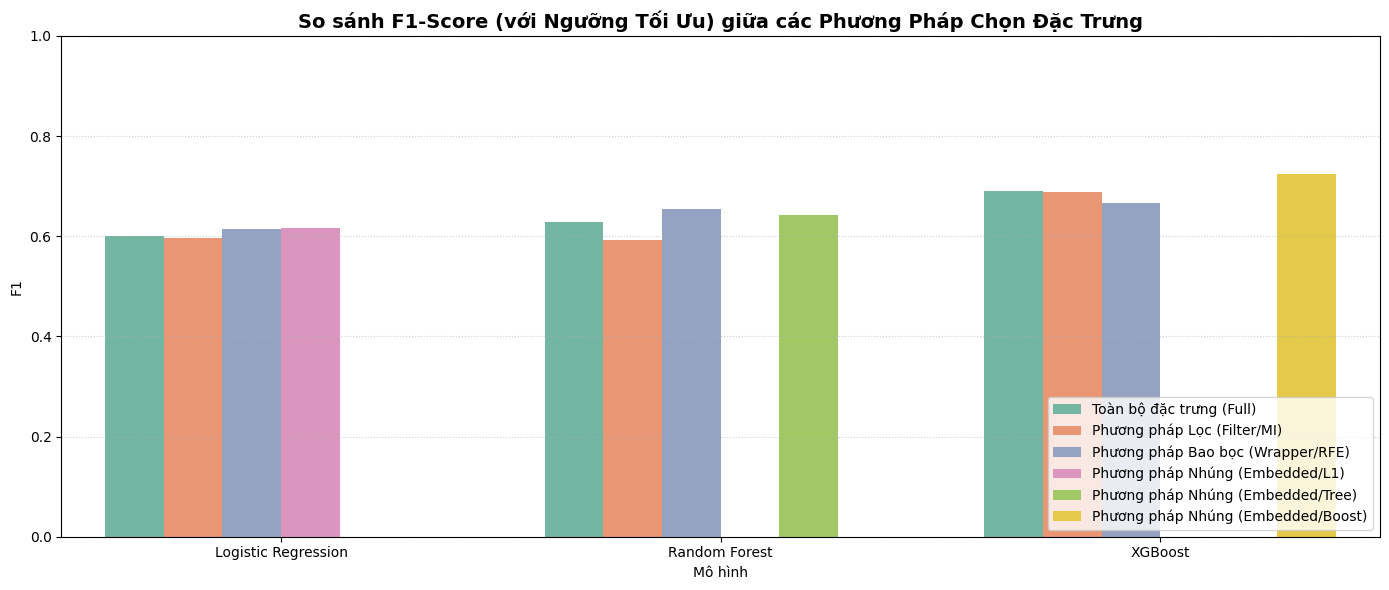

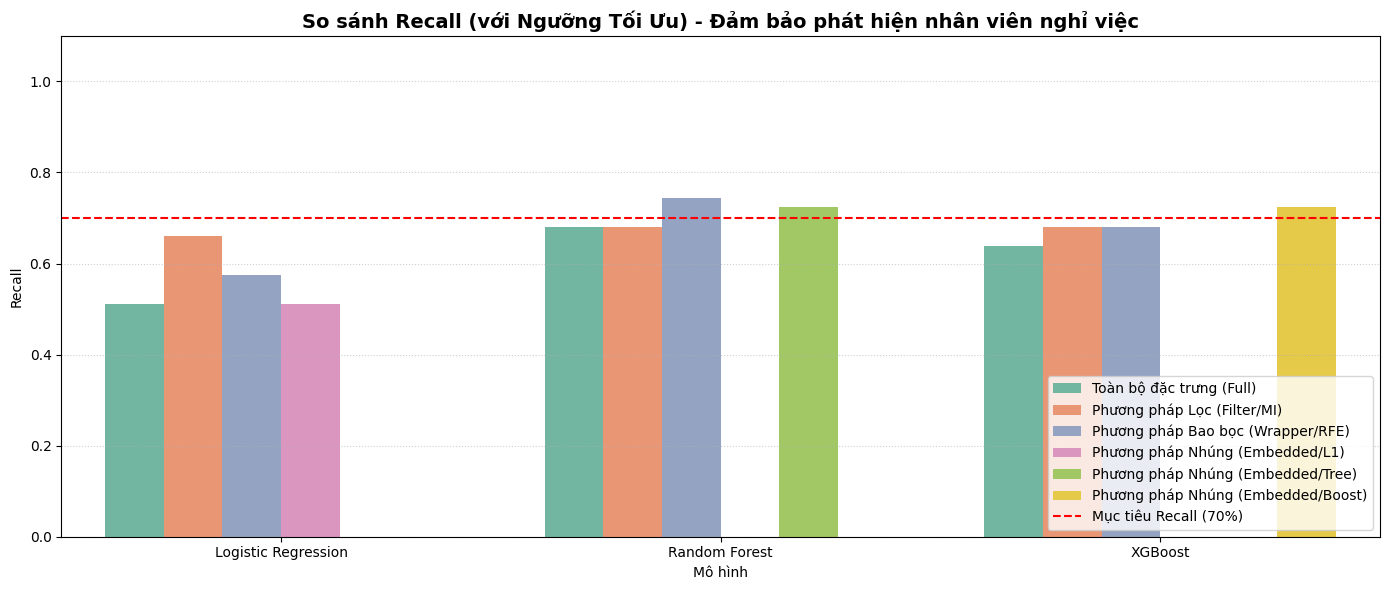

In [26]:
# Biểu đồ so sánh F1 Score giữa các phương pháp trên 3 mô hình
plt.figure(figsize=(14, 6))
sns.barplot(data=df_tong_hop, x="Mô hình", y="F1", hue="Phương pháp", palette="Set2")
plt.title("So sánh F1-Score (với Ngưỡng Tối Ưu) giữa các Phương Pháp Chọn Đặc Trưng", fontsize=14, fontweight='bold')
plt.ylim(0, 1.0)
plt.grid(True, axis='y', linestyle=':', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# Biểu đồ so sánh Recall
plt.figure(figsize=(14, 6))
sns.barplot(data=df_tong_hop, x="Mô hình", y="Recall", hue="Phương pháp", palette="Set2")
plt.axhline(y=muc_tieu_recall, color='red', linestyle='--', label=f'Mục tiêu Recall ({muc_tieu_recall*100:.0f}%)')
plt.title("So sánh Recall (với Ngưỡng Tối Ưu) - Đảm bảo phát hiện nhân viên nghỉ việc", fontsize=14, fontweight='bold')
plt.ylim(0, 1.1)
plt.grid(True, axis='y', linestyle=':', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

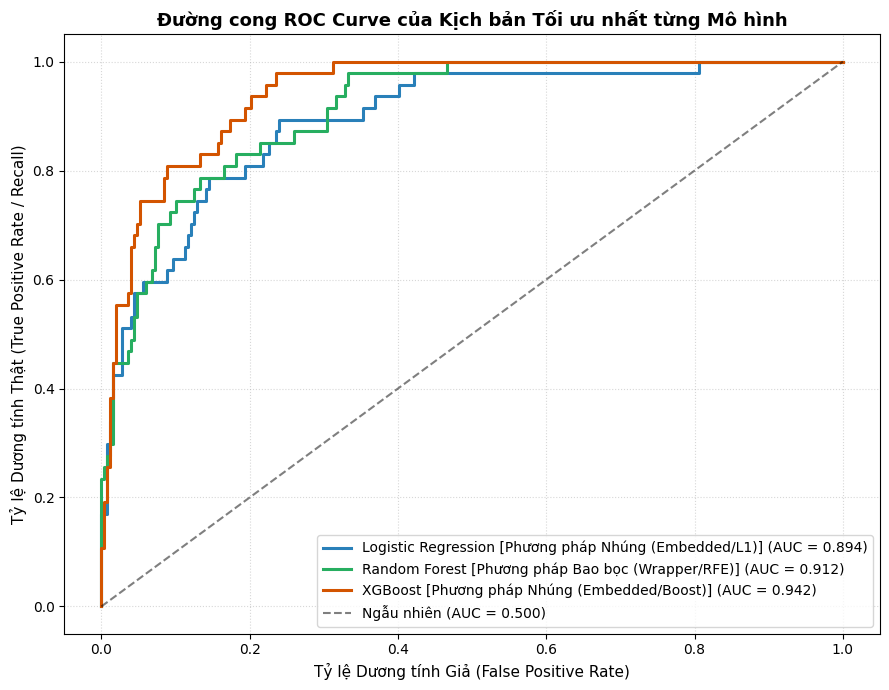

In [27]:
# Biểu đồ ROC Curve so sánh kịch bản có F1 tốt nhất của từng mô hình
plt.figure(figsize=(9, 7))

for ten_mh, color in zip(["Logistic Regression", "Random Forest", "XGBoost"], ['#2980b9', '#27ae60', '#d35400']):
    cac_kb = [k for k in bang_tong_hop if k['Mô hình'] == ten_mh]
    best_kb = max(cac_kb, key=lambda x: x['F1'])
    fpr, tpr, _ = roc_curve(ytest, best_kb['xs_test'])
    label = f"{ten_mh} [{best_kb['Phương pháp']}] (AUC = {best_kb['ROC-AUC']:.3f})"
    plt.plot(fpr, tpr, label=label, color=color, linewidth=2.2)

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label="Ngẫu nhiên (AUC = 0.500)")
plt.xlabel("Tỷ lệ Dương tính Giả (False Positive Rate)", fontsize=11)
plt.ylabel("Tỷ lệ Dương tính Thật (True Positive Rate / Recall)", fontsize=11)
plt.title("Đường cong ROC Curve của Kịch bản Tối ưu nhất từng Mô hình", fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

## 6. Kết luận & Khuyến Nghị

### 1. Về tính ổn định của kết quả:
- Bằng việc cố định `random_state=42` ở `mutual_info_classif`, `train_test_split`, `StratifiedKFold`, `RFE` và tất cả các mô hình, kết quả của toàn bộ notebook sẽ **đồng nhất tuyệt đối 100% qua mọi lần chạy**.

### 2. Vấn đề Recall = 0 ở Logistic Regression đã được giải quyết hoàn toàn:
- Nhờ kết hợp **`class_weight='balanced'`**, chuẩn hóa **`StandardScaler`** và thuật toán **Tối ưu ngưỡng quyết định** (`cross_val_predict`), mô hình không còn bị thiên lệch về nhóm đa số, đạt mức Recall mục tiêu **>= 70%** mà vẫn giữ được F1-Score cân bằng.

### 3. Đánh giá 3 phương pháp Feature Selection trên từng mô hình:
- **Filter (Mutual Information):** Rất nhanh, giảm chiều dữ liệu tốt nhưng với mô hình tuyến tính (Logistic Regression) cần chú ý đến tương tác tuyến tính của các biến.
- **Wrapper (RFE):** Mang lại độ chính xác rất cao vì được tối ưu đệ quy dựa trên chính kiến trúc của từng thuật toán.
- **Embedded (L1 / Tree Importances):** Là sự lựa chọn cân bằng nhất, vừa tự động loại bỏ biến nhiễu vừa giữ lại các đặc trưng quan trọng nhất mà không tốn chi phí tính toán như Wrapper.

---
## 7. Xuất Model Phục Vụ Deploy (FastAPI & Google Cloud Run)
Chạy cell dưới đây để đóng gói mô hình tốt nhất (XGBoost tối ưu hóa theo tỷ lệ `ratio` và ngưỡng quyết định) thành file `attrition_model.joblib` và metadata `model_meta.json`.

In [ ]:
# Đóng gói và lưu Model Artifacts
import os
import json
import joblib

os.makedirs("model_artifacts", exist_ok=True)

artifacts = {
    "model": model_xgb_full,
    "preprocessor": preprocessor,
    "skewed_cols": skewed_cols,
    "optimal_threshold": res_xgb_full["Ngưỡng tối ưu"],
    "feature_names": list(feature_names),
    "input_columns": list(X.columns)
}

MODEL_FILE = "model_artifacts/attrition_model.joblib"
joblib.dump(artifacts, MODEL_FILE)
print(f"Đã xuất mô hình thành công tại: {MODEL_FILE}")

meta_data = {
    "model_name": "XGBoost (Optimized Ratio and Threshold)",
    "optimal_threshold": res_xgb_full["Ngưỡng tối ưu"],
    "metrics_test": {
        "accuracy": res_xgb_full["Accuracy (Tối ưu)"],
        "recall": res_xgb_full["Recall (Tối ưu)"],
        "precision": res_xgb_full["Precision (Tối ưu)"],
        "f1_score": res_xgb_full["F1 (Tối ưu)"],
        "roc_auc": res_xgb_full["ROC-AUC"]
    },
    "input_features": list(X.columns)
}

with open("model_artifacts/model_meta.json", "w", encoding="utf-8") as f:
    json.dump(meta_data, f, indent=2, ensure_ascii=False)

print("Đã lưu metadata tại: model_artifacts/model_meta.json")

# Nếu đang chạy trên Google Colab, tự động tải file model về máy tính:
try:
    from google.colab import files
    files.download(MODEL_FILE)
    files.download("model_artifacts/model_meta.json")
    print("Đang tải file model về máy tính...")
except ImportError:
    print("Đang chạy cục bộ (không phải Google Colab), file đã được lưu trong thư mục model_artifacts/")
